# Data pre-processing (Task 1)

In [50]:
# Libraries used in this notebook
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

## 1. Loading the data

In [9]:
# Load the data and take a first look
data = pd.read_csv('Project_Data_EE4C12_S&S_EMG.csv')
data

,time,channel1,channel2,channel3,channel4,channel5,channel6,channel7,channel8,class,label
0,1,0.00001,-0.00002,-0.00001,-0.00003,0.00000,-0.00001,0.00000,-0.00001,0,1
1,5,0.00001,-0.00002,-0.00001,-0.00003,0.00000,-0.00001,0.00000,-0.00001,0,1
2,6,-0.00001,0.00001,0.00002,0.00000,0.00001,-0.00002,-0.00001,0.00001,0,1
3,7,-0.00001,0.00001,0.00002,0.00000,0.00001,-0.00002,-0.00001,0.00001,0,1
4,8,-0.00001,0.00001,0.00002,0.00000,0.00001,-0.00002,-0.00001,0.00001,0,1
...,...,...,...,...,...,...,...,...,...,...,...
4237902,50962,0.00001,-0.00001,-0.00002,-0.00004,-0.00012,0.00000,0.00002,0.00002,0,36
4237903,50963,0.00001,-0.00001,-0.00002,-0.00004,-0.00012,0.00000,0.00002,0.00002,0,36
4237904,50964,0.00001,-0.00001,-0.00002,-0.00004,-0.00012,0.00000,0.00002,0.00002,0,36
4237905,50965,0.00001,-0.00001,-0.00002,-0.00004,-0.00012,0.00000,0.00002,0.00002,0,36


In [10]:
# According to the project description the 'label' column is the subject number, so we rename it
data = data.rename(columns={'label': 'subject'})

channels = ['channel1', 'channel2', 'channel3', 'channel4', 'channel5', 'channel6', 'channel7', 'channel8']
class_names = {0: 'unmarked', 1: 'rest', 2: 'fist', 3: 'wrist flexion', 4: 'wrist extension',
               5: 'radial deviation', 6: 'ulnar deviation', 7: 'extended palm'}

print('Shape of the data:', data.shape)
print(data.dtypes)

Shape of the data: (4237907, 11)
time          int64
channel1    float64
channel2    float64
channel3    float64
channel4    float64
channel5    float64
channel6    float64
channel7    float64
channel8    float64
class         int64
subject       int64
dtype: object


In [11]:
# Check for missing values in each column
print(data.isna().sum())

time        0
channel1    0
channel2    0
channel3    0
channel4    0
channel5    0
channel6    0
channel7    0
channel8    0
class       0
subject     0
dtype: int64


In [12]:
# Basic statistics of the EMG channels
data[channels].describe()

,channel1,channel2,channel3,channel4,channel5,channel6,channel7,channel8
count,4.237907e+06,4.237907e+06,4.237907e+06,4.237907e+06,4.237907e+06,4.237907e+06,4.237907e+06,4.237907e+06
mean,-7.911478e-06,-9.416073e-06,-9.548730e-06,-9.637835e-06,-1.599724e-05,-1.085528e-05,-9.364639e-06,-9.696860e-06
std,1.631111e-04,1.192229e-04,1.241846e-04,2.257728e-04,2.724188e-04,2.151405e-04,1.527311e-04,1.720934e-04
min,-1.280000e-03,-1.280000e-03,-1.280000e-03,-1.280000e-03,-1.280000e-03,-1.280000e-03,-1.280000e-03,-1.280000e-03
25%,-3.000000e-05,-4.000000e-05,-4.000000e-05,-6.000000e-05,-8.000000e-05,-6.000000e-05,-4.000000e-05,-3.000000e-05
50%,-1.000000e-05,-1.000000e-05,-1.000000e-05,-1.000000e-05,-1.000000e-05,-1.000000e-05,-1.000000e-05,-1.000000e-05
75%,2.000000e-05,2.000000e-05,3.000000e-05,4.000000e-05,5.000000e-05,3.000000e-05,2.000000e-05,1.000000e-05
max,1.270000e-03,1.270000e-03,1.270000e-03,1.270000e-03,1.270000e-03,1.270000e-03,1.270000e-03,1.270000e-03


## 2. Class distribution

class
0    2725157
1     250055
2     243193
3     249494
4     251570
5     251733
6     253009
7      13696
Name: count, dtype: int64


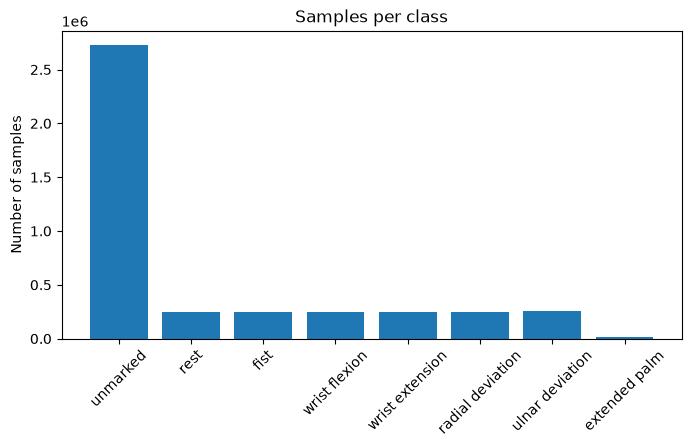

In [13]:
# Number of samples per class
counts = data['class'].value_counts().sort_index()
print(counts)

plt.figure(figsize=(8,4))
plt.bar([class_names[c] for c in counts.index], counts.values)
plt.xticks(rotation=45)
plt.ylabel('Number of samples')
plt.title('Samples per class')
plt.show()

In [14]:
# Number of samples per subject and class
per_subject = pd.crosstab(data['subject'], data['class'])
print('Subjects that performed class 7:', per_subject.index[per_subject[7] > 0].tolist())
per_subject

Subjects that performed class 7: [11, 30]


class,0,1,2,3,4,5,6,7
subject,,,,,,,,
1,78682,7311,6806,7329,6824,7075,7143,0
2,94654,7140,6777,6815,6812,6856,7372,0
3,67770,6443,6301,6486,6421,6278,6086,0
4,72578,6471,6598,6875,7193,7423,7060,0
5,68057,6506,6806,6874,6724,6098,6183,0
6,61128,5814,6243,6663,6688,7094,5989,0
7,82641,7523,7651,8383,8923,8414,9105,0
8,80264,6468,6537,5939,6027,6237,6476,0
9,90407,7083,6019,5838,5776,6050,6474,0


<br> Only 2 subjects performed class 7 (extended palm) <br>

## 3. Time and sampling rate

In [15]:
# Time difference (in ms) between consecutive samples, computed per subject
dt = data.groupby('subject')['time'].diff()
print(dt.value_counts().head(10))

time
1.0     4106924
2.0      108045
3.0       20752
4.0        1252
8.0         180
5.0         165
7.0         148
9.0         143
6.0          77
10.0         75
Name: count, dtype: int64


In [16]:
# A negative time step means the time restarts: this is where the second series of a subject begins
print('Number of time restarts:', (dt < 0).sum())

# Give every sample a series number (1 or 2) within its subject
data['series'] = (dt < 0).groupby(data['subject']).cumsum() + 1
print(data.groupby('subject')['series'].max().value_counts())

Number of time restarts: 36
series
2    36
Name: count, dtype: int64


In [17]:
# Duration of each series in seconds
duration = data.groupby(['subject', 'series'])['time'].agg(['min', 'max'])
duration['seconds'] = (duration['max'] - duration['min']) / 1000
print(duration['seconds'].describe())

count    72.000000
mean     61.263292
std       9.138398
min      47.446000
25%      53.699000
50%      60.163000
75%      65.473250
max      97.142000
Name: seconds, dtype: float64


In [18]:
# How often is a sample exactly the same as the previous one (on all 8 channels)?
same_as_prev = (data[channels].diff() == 0).all(axis=1)
print('Fraction of repeated samples:', same_as_prev.mean())

# Length of the runs of identical samples
run_id = (~same_as_prev).cumsum()
run_lengths = run_id.value_counts()
print('Run length -> number of runs')
print(run_lengths.value_counts().sort_index().head(10))

# Effective sampling rate = number of new (non-repeated) samples per second
total_seconds = dt[dt > 0].sum() / 1000
print('Effective sampling rate (Hz):', (~same_as_prev).sum() / total_seconds)

Fraction of repeated samples: 0.8914742584016119
Run length -> number of runs
count
1     144072
2      42501
3       1967
4       2629
5       5946
6      11215
7      14979
8      15053
9      14161
10      3426
Name: count, dtype: int64
Effective sampling rate (Hz): 104.26807606603283


## 4. Signal values

In [19]:
# The values look quantized: check how many different values a channel has
print('Number of unique values in channel1:', data['channel1'].nunique())
print(np.sort(data['channel1'].unique())[:10])

Number of unique values in channel1: 256
[-0.00128 -0.00127 -0.00126 -0.00125 -0.00124 -0.00123 -0.00122 -0.00121
 -0.0012  -0.00119]


In [20]:
# The sensor has a maximum value; samples at this value are clipped
max_value = data[channels].abs().max().max()
clipped = (data[channels].abs() >= max_value)
print('Max absolute value:', max_value)
print('Fraction of clipped samples per channel:')
print(clipped.mean())

Max absolute value: 0.00128
Fraction of clipped samples per channel:
channel1    0.000287
channel2    0.000129
channel3    0.000066
channel4    0.000731
channel5    0.001484
channel6    0.000382
channel7    0.000252
channel8    0.000392
dtype: float64


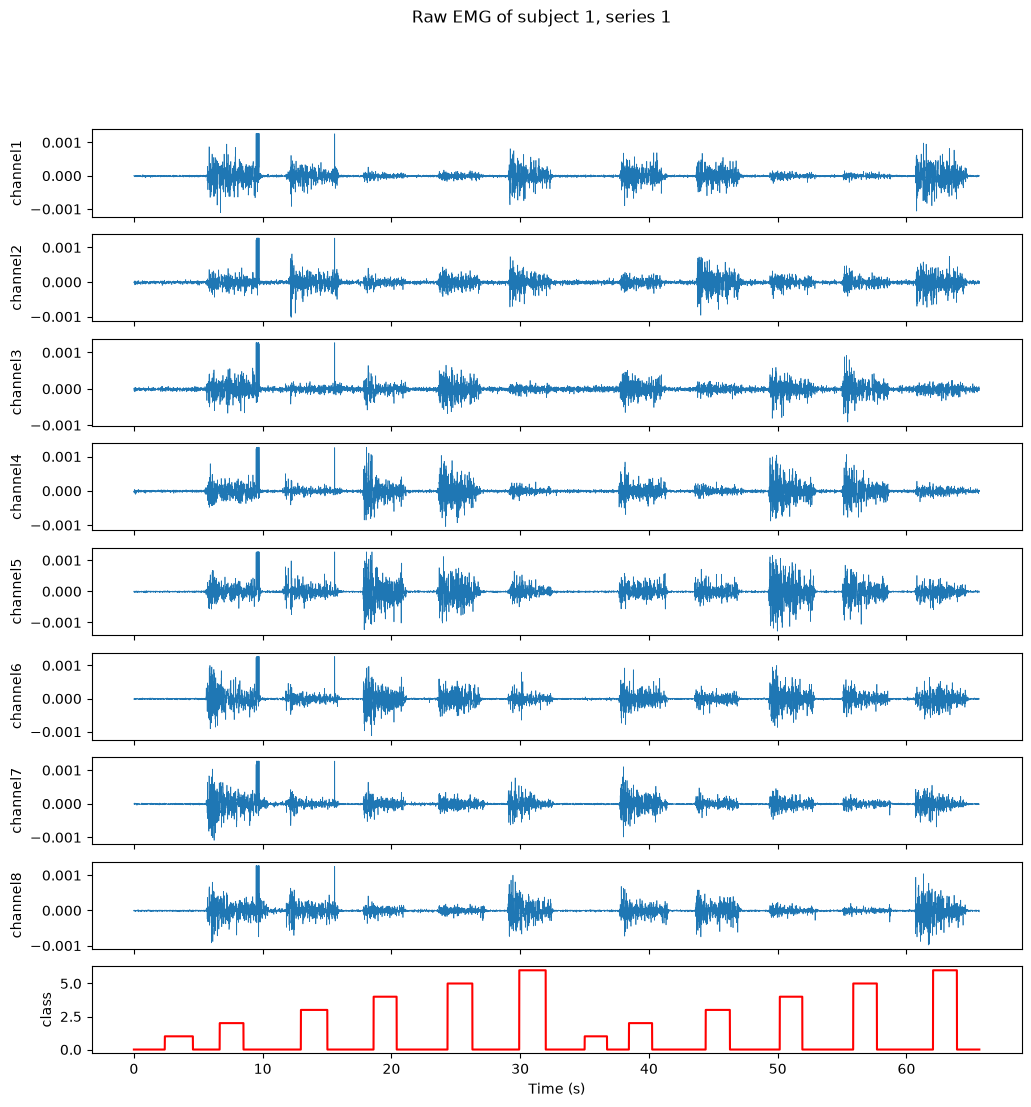

In [21]:
# Plot the raw signals of one subject (series 1) together with the class
s = data[(data['subject'] == 1) & (data['series'] == 1)]

fig, axes = plt.subplots(9, 1, figsize=(12,12), sharex=True)
for i, ch in enumerate(channels):
    axes[i].plot(s['time'] / 1000, s[ch], linewidth=0.5)
    axes[i].set_ylabel(ch)
axes[8].plot(s['time'] / 1000, s['class'], color='red')
axes[8].set_ylabel('class')
axes[8].set_xlabel('Time (s)')
plt.suptitle('Raw EMG of subject 1, series 1')
plt.show()

## 5. Gesture blocks

In [22]:
# Split the data into continuous blocks with the same class (new block at a class, series or subject change)
new_block = (data['class'] != data['class'].shift()) | (data['series'] != data['series'].shift()) | (data['subject'] != data['subject'].shift())
block_id = new_block.cumsum()

blocks = data.groupby(block_id).agg(subject=('subject', 'first'), series=('series', 'first'), cls=('class', 'first'),
                                     start=('time', 'first'), end=('time', 'last'), n_samples=('time', 'size'))
blocks['seconds'] = (blocks['end'] - blocks['start']) / 1000

# Duration of the gesture blocks per class (expected: about 3 seconds)
blocks.groupby('cls')['seconds'].describe()

,count,mean,std,min,25%,50%,75%,max
cls,,,,,,,,
0,940.0,3.023730,1.546262,0.659,2.08750,3.0335,3.79300,34.970
1,144.0,1.799153,0.395730,1.135,1.60350,1.7490,1.90450,4.596
2,144.0,1.746132,0.199073,1.118,1.61925,1.7345,1.84600,2.431
3,144.0,1.793806,0.298868,1.252,1.60600,1.7495,1.91025,3.278
4,144.0,1.806688,0.298462,1.343,1.62000,1.7860,1.89550,3.182
5,144.0,1.806201,0.293618,1.317,1.63600,1.7620,1.95100,2.821
6,144.0,1.817090,0.316997,1.270,1.60000,1.7780,1.96025,3.334
7,8.0,1.765875,0.135242,1.542,1.68125,1.7660,1.86800,1.950


In [23]:
# How many times is each gesture performed per subject and series?
blocks[blocks['cls'] != 0].groupby(['subject', 'series'])['cls'].count().value_counts()

cls
12    68
14     4
Name: count, dtype: int64

## 6. Can single samples separate the classes?

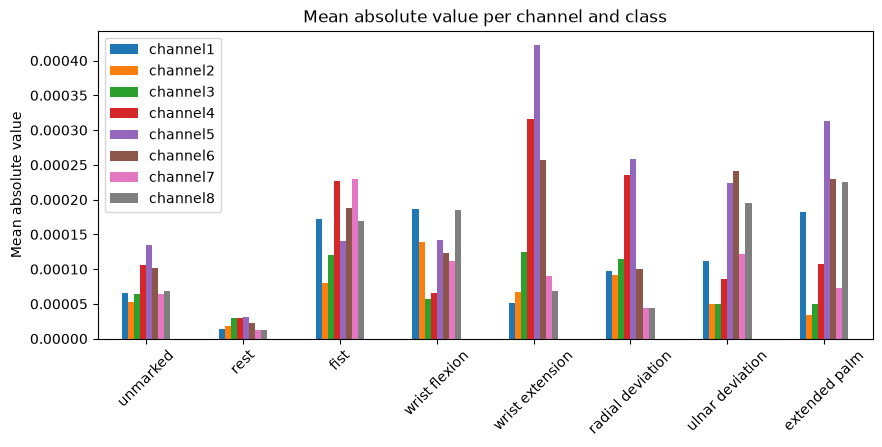

In [24]:
# Average signal strength (mean absolute value) per channel for each class
mav_per_class = data[channels].abs().groupby(data['class']).mean()
mav_per_class.index = [class_names[c] for c in mav_per_class.index]

mav_per_class.plot(kind='bar', figsize=(10,4))
plt.ylabel('Mean absolute value')
plt.title('Mean absolute value per channel and class')
plt.xticks(rotation=45)
plt.show()

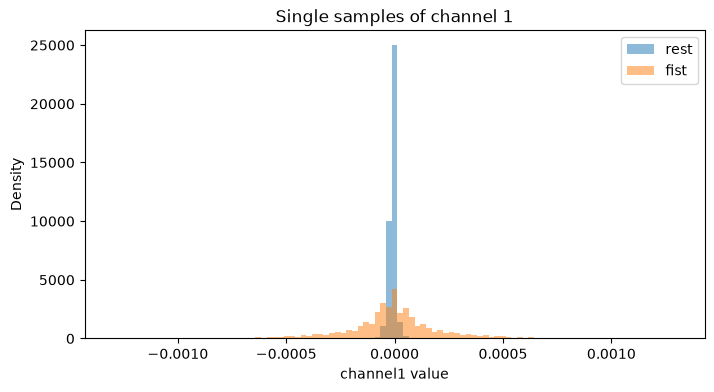

In [25]:
# Distribution of single samples of channel 1 for 'rest' and 'fist'
bins = np.linspace(-0.0013, 0.0013, 100)
plt.figure(figsize=(8,4))
plt.hist(data.loc[data['class'] == 1, 'channel1'], bins=bins, alpha=0.5, density=True, label='rest')
plt.hist(data.loc[data['class'] == 2, 'channel1'], bins=bins, alpha=0.5, density=True, label='fist')
plt.xlabel('channel1 value')
plt.ylabel('Density')
plt.title('Single samples of channel 1')
plt.legend()
plt.show()

## Observations

- **Class balance:** class 0 (unmarked) is about 64% of all rows (2.7 million). Gestures 1-6 are balanced, with about 250,000 rows each.
  Class 7 (extended palm) has only about 14,000 rows.
- **Class 7:** only subjects 11 and 30 performed it, so it cannot be learned or tested for other subjects.
- **Data quality:** there are no missing values. Every subject has exactly 2 series (the time restarts once per subject), and each series lasts about 47-97 s.
- **Sampling rate:** rows are logged about every 1 ms, but 89% of the rows are an exact copy of the previous row.
  The number of new samples is about **104 per second**, much lower than the logging rate (studied further in section 8).
- **Signal values:** every channel has only 256 different values (steps of 0.00001, from -0.00128 to 0.00127), so the signal is
  quantized to 8 bits. A very small part of the samples (at most 0.15% per channel) is at the maximum value, so clipping is rare.
- **Raw signals (subject 1):** during a gesture the signal is much larger than at rest or during the pause, and different gestures
  activate different channels. There are short spikes on all 8 channels at the same moment (e.g. at about 9.5 s), probably
  artifacts from movement, which reach the clipping value.
- **Block durations:** the description says that every gesture lasts 3 s, but a labelled gesture block is on average only about 1.8 s.
  The unmarked parts (class 0) are about 3 s and probably also contain the transitions into and out of a gesture.
  Every gesture is performed twice per series (12 gesture blocks per series; 14 for the two subjects with class 7).
- **Single samples vs. signal strength:** single samples of 'rest' and 'fist' are both centred around 0 and overlap strongly, so
  one sample tells almost nothing about the gesture. The **mean absolute value** over time, however, is very different
  per class and per channel (e.g. rest is close to 0 everywhere, wrist extension is high on channels 4-6). The information is
  therefore in the signal strength over a short period, which is why we use windows and features (section 9).

## 7. Data preparation

Choices:
- **Class 0 (unmarked) is removed.** It is the pause between gestures (median block of about 3 s) and probably the transitions into and out of a gesture, so it is not one gesture.
- **Class 7 (extended palm) is removed.** Only subjects 11 and 30 performed it, so there is too little data to learn it and it cannot be tested on other subjects.

In [26]:
# Give every sample the number of the gesture block it belongs to (computed in section 5)
data['block'] = block_id

In [27]:
# Remove unmarked data (class 0) and extended palm (class 7)
data_prep = data[(data['class'] != 0) & (data['class'] != 7)].reset_index(drop=True)

print('Samples before:', len(data))
print('Samples after:', len(data_prep))
print(data_prep['class'].value_counts().sort_index())

Samples before: 4237907
Samples after: 1499054
class
1    250055
2    243193
3    249494
4    251570
5    251733
6    253009
Name: count, dtype: int64


In [28]:
# Check that every subject still has all 6 gestures, performed twice in each series (12 blocks per series)
blocks_per_series = data_prep.groupby(['subject', 'series'])['block'].nunique()
print(blocks_per_series.value_counts())

block
12    72
Name: count, dtype: int64


In [29]:
# Keep only the columns we need
data_prep = data_prep[['subject', 'series', 'block', 'time'] + channels + ['class']]
data_prep

,subject,series,block,time,channel1,channel2,channel3,channel4,channel5,channel6,channel7,channel8,class
0,1,1,2,2400,-0.00001,0.00000,-0.00001,0.00000,0.00000,-0.00001,-0.00001,0.00001,1
1,1,1,2,2401,-0.00001,-0.00002,0.00000,-0.00001,-0.00001,-0.00001,-0.00003,-0.00002,1
2,1,1,2,2402,-0.00001,-0.00002,0.00000,-0.00001,-0.00001,-0.00001,-0.00003,-0.00002,1
3,1,1,2,2403,-0.00001,-0.00002,0.00000,-0.00001,-0.00001,-0.00001,-0.00003,-0.00002,1
4,1,1,2,2404,-0.00001,-0.00002,0.00000,-0.00001,-0.00001,-0.00001,-0.00003,-0.00002,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1499049,36,2,1811,50226,0.00009,0.00001,0.00003,0.00001,-0.00003,-0.00008,0.00004,0.00000,6
1499050,36,2,1811,50227,0.00009,0.00001,0.00003,0.00001,-0.00003,-0.00008,0.00004,0.00000,6
1499051,36,2,1811,50228,0.00009,0.00001,0.00003,0.00001,-0.00003,-0.00008,0.00004,0.00000,6
1499052,36,2,1811,50229,0.00014,0.00003,-0.00001,0.00001,-0.00012,0.00006,-0.00007,-0.00013,6


## 8. Data cleaning: removing repeated samples

About 89% of the rows are an exact copy of the previous row (all 8 channels identical).

**Assumption:** these copies are not new measurements, but the last received values written again by the recording software
(rows are logged about every 1 ms, while new values arrive only about 105 times per second).
This is not stated in the project description; it is our interpretation, based on the following evidence:
- 8 independent, noisy channels are rarely exactly equal to the previous sample by chance.
- The copies come in runs of typically 5-10 rows.
- After removing them, the sampling rate is about 105 Hz for **every** class (checked below). If the copies were real
  measurements that happened to be equal, they would be much more common at rest (small signal) than during a gesture.

Under this assumption the copies carry no information about the muscle: they make a window look longer than the real
signal is and they distort features such as waveform length and frequency features.
We therefore keep only the samples that differ from the previous sample **in the same block**.

In [30]:
# A sample is a repeat if all 8 channels are equal to the previous sample in the same block
previous = data_prep.groupby('block')[channels].shift()
is_repeat = (data_prep[channels] == previous).all(axis=1)
print('Fraction of repeated samples:', is_repeat.mean())

Fraction of repeated samples: 0.8910779731750824


In [31]:
# Keep only the new (non-repeated) samples
data_clean = data_prep[~is_repeat].reset_index(drop=True)

print('Samples before:', len(data_prep))
print('Samples after:', len(data_clean))
print(data_clean['class'].value_counts().sort_index())

Samples before: 1499054
Samples after: 163280
class
1    27352
2    26651
3    27016
4    27456
5    27244
6    27561
Name: count, dtype: int64


count    162416.000000
mean          9.504538
std           8.390471
min           1.000000
25%           1.000000
50%           8.000000
75%          15.000000
max         151.000000
Name: time, dtype: float64


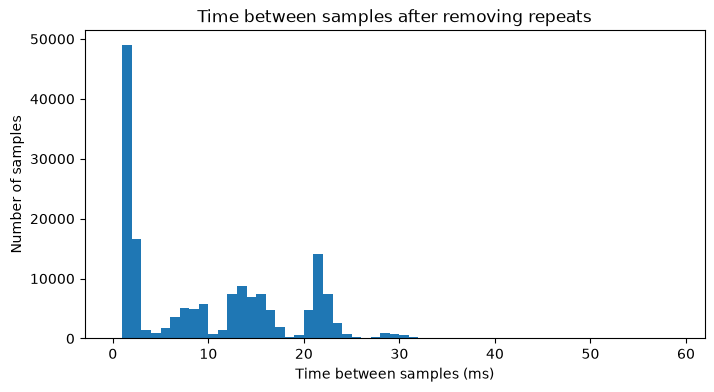

In [32]:
# Time (in ms) between the samples that are left, within each block
dt_clean = data_clean.groupby('block')['time'].diff()
print(dt_clean.describe())

plt.figure(figsize=(8,4))
plt.hist(dt_clean, bins=np.arange(0, 60, 1))
plt.xlabel('Time between samples (ms)')
plt.ylabel('Number of samples')
plt.title('Time between samples after removing repeats')
plt.show()

In [33]:
# Effective sampling rate per block = number of samples / duration of the block
per_block = data_clean.groupby('block').agg(cls=('class', 'first'), n_samples=('time', 'size'),
                                            start=('time', 'first'), end=('time', 'last'))
per_block['rate_hz'] = per_block['n_samples'] / ((per_block['end'] - per_block['start']) / 1000)

# If real (not copied) samples were removed during rest, the rate of class 1 would be lower than the others
per_block.groupby('cls')['rate_hz'].describe()

,count,mean,std,min,25%,50%,75%,max
cls,,,,,,,,
1,144.0,105.934563,8.066930,74.449077,100.806754,105.438569,111.894603,126.962142
2,144.0,106.485327,8.279762,86.725664,100.540946,106.008981,111.647901,137.181875
3,144.0,104.975579,8.260304,86.862106,99.408251,104.618900,110.259679,126.477541
4,144.0,105.966068,8.643368,79.740106,100.355534,105.066003,110.856881,129.690949
5,144.0,105.180912,8.314292,85.904416,100.122482,103.755169,109.698766,130.528587
6,144.0,105.832242,7.875320,88.453747,100.456039,105.658101,110.151852,125.296912


In [34]:
# Number of samples per gesture block after cleaning (this limits the window length)
print(per_block['n_samples'].describe())

count    864.000000
mean     188.981481
std       36.140830
min      119.000000
25%      166.000000
50%      185.000000
75%      204.000000
max      487.000000
Name: n_samples, dtype: float64


In [35]:
# Large gaps: no new sample for more than 50 ms
print('Gaps longer than 50 ms:', (dt_clean > 50).sum(), 'out of', dt_clean.count())

Gaps longer than 50 ms: 56 out of 162416


**Extra test of the assumption.** If the repeats were real measurements that are equal by chance, they would be common
when the signal is small (few possible values) and very rare when the signal is large (8 channels changing a lot).
If they are copies made by the recording software, the fraction of repeats does not depend on the signal size.
We split all samples into 10 equally large groups by signal size (mean absolute value over the 8 channels) and compare the fraction of repeats.

(-0.00099875, 2e-05]    0.891818
(2e-05, 4.25e-05]       0.890142
(4.25e-05, 6.38e-05]    0.890960
(6.38e-05, 8.38e-05]    0.891878
(8.38e-05, 0.000105]    0.890604
(0.000105, 0.000128]    0.891401
(0.000128, 0.000156]    0.891619
(0.000156, 0.000194]    0.890944
(0.000194, 0.000252]    0.891107
(0.000252, 0.00117]     0.890316
dtype: float64


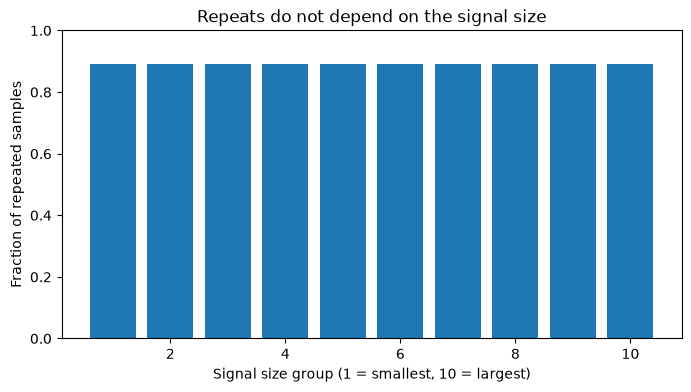

In [36]:
# Signal size of every sample: mean absolute value over the 8 channels
amplitude = data_prep[channels].abs().mean(axis=1)

# Split the samples into 10 groups (deciles) from smallest to largest signal
amplitude_group = pd.qcut(amplitude, 10)

# Fraction of repeated samples in each group
repeats_per_group = is_repeat.groupby(amplitude_group).mean()
print(repeats_per_group)

plt.figure(figsize=(8,4))
plt.bar(range(1, 11), repeats_per_group.values)
plt.ylim(0, 1)
plt.xlabel('Signal size group (1 = smallest, 10 = largest)')
plt.ylabel('Fraction of repeated samples')
plt.title('Repeats do not depend on the signal size')
plt.show()

Results:
- After removing repeats, about 163,000 samples remain (about 27,000 per class).
- The effective sampling rate is about **105 Hz** and is the same for every class, so there is no sign that removing repeats removed real samples during rest (this supports the assumption above).
- The fraction of repeats is 89% for every signal size, from the smallest to the largest signals. Real equal-by-chance samples would almost disappear for large signals, so this strongly supports the assumption that the repeats are copies.
- The time between samples is irregular: new samples often arrive in pairs (1-2 ms apart) followed by a pause (about 8-21 ms).
- A gesture block contains about 185 samples (minimum 119). Gaps longer than 50 ms are very rare and are ignored.

Decision: we treat the cleaned samples as one sequence at about 105 Hz and define windows by a **number of samples**.

## 9. Windowing and feature construction

A single EMG sample says almost nothing about the gesture (section 6): the information is in the signal over a short period.
We therefore cut every gesture block into **windows** and compute features per window and per channel.

- **Window length:** 20 samples (about 190 ms at 105 Hz), with 50% overlap (a new window every 10 samples).
  A gesture block has at least 119 samples, so every block gives several windows. Windows never cross block borders.
- **Features** (computed for each of the 8 channels, so 5 x 8 = 40 features per window):
  - **MAV** (mean absolute value): average signal strength.
  - **RMS** (root mean square): signal power.
  - **WL** (waveform length, per sample): average size of the jumps between consecutive samples.
  - **ZC** (zero crossings, per sample): how often the signal changes sign.
  - **MNF** (mean frequency): average frequency of the power spectrum of the window.
- All features are **averages per sample**, not sums, so they do not depend on the number of samples in a window.
- MNF assumes evenly spaced samples at 105 Hz; our samples are not exactly evenly spaced (section 8), so MNF is only an approximation.

In [37]:
# Settings
fs = 105            # effective sampling rate in Hz (section 8)
window_size = 20    # samples per window (about 190 ms)
step = 10           # a new window every 10 samples (50% overlap)

feature_types = ['MAV', 'RMS', 'WL', 'ZC', 'MNF']
feature_names = [f'{f}_ch{i}' for f in feature_types for i in range(1, 9)]
print('Number of features:', len(feature_names))

Number of features: 40


In [38]:
def extract_features(window, fs):
    # window: array of shape (number of samples, 8 channels); every feature gives one value per channel
    mav = np.mean(np.abs(window), axis=0)
    rms = np.sqrt(np.mean(window**2, axis=0))
    wl = np.mean(np.abs(np.diff(window, axis=0)), axis=0)
    zc = np.mean(window[1:] * window[:-1] < 0, axis=0)

    # Mean frequency: weighted average of the frequencies, weighted by the power at each frequency
    power = np.abs(np.fft.rfft(window - window.mean(axis=0), axis=0))**2
    freqs = np.fft.rfftfreq(len(window), d=1/fs)
    mnf = np.sum(freqs[:, None] * power, axis=0) / (np.sum(power, axis=0) + 1e-20)

    return np.concatenate([mav, rms, wl, zc, mnf])

In [39]:
def make_feature_table(data, window_size, step, fs):
    # Cut every gesture block into windows and compute the features of each window
    rows = []
    for block, b in data.groupby('block'):
        signals = b[channels].values
        for start in range(0, len(b) - window_size + 1, step):
            window = signals[start:start + window_size]
            rows.append(list(extract_features(window, fs)) + [b['class'].iloc[0], b['subject'].iloc[0], b['series'].iloc[0], block])
    return pd.DataFrame(rows, columns=feature_names + ['class', 'subject', 'series', 'block'])

features = make_feature_table(data_clean, window_size, step, fs)
print('Shape of the feature table:', features.shape)
print(features['class'].value_counts().sort_index())

Shape of the feature table: (15069, 44)
class
1    2523
2    2461
3    2491
4    2537
5    2513
6    2544
Name: count, dtype: int64


In [40]:
features.head()

,MAV_ch1,MAV_ch2,MAV_ch3,MAV_ch4,MAV_ch5,MAV_ch6,MAV_ch7,MAV_ch8,RMS_ch1,RMS_ch2,...,MNF_ch3,MNF_ch4,MNF_ch5,MNF_ch6,MNF_ch7,MNF_ch8,class,subject,series,block
0,0.000013,0.000017,0.000022,0.000015,0.000011,0.000010,0.000012,0.000012,0.000015,0.000023,...,25.379153,30.307469,35.088014,24.641942,30.107122,25.303318,1,1,1,2
1,0.000012,0.000019,0.000026,0.000014,0.000012,0.000013,0.000010,0.000012,0.000015,0.000023,...,32.825763,29.016135,35.681841,23.681805,25.491205,24.853026,1,1,1,2
2,0.000011,0.000016,0.000027,0.000011,0.000015,0.000014,0.000012,0.000011,0.000014,0.000022,...,38.383079,32.598867,30.216709,28.782141,32.119405,27.544078,1,1,1,2
3,0.000010,0.000015,0.000025,0.000016,0.000014,0.000011,0.000011,0.000013,0.000014,0.000021,...,34.024739,29.275860,31.570620,29.036083,25.123811,27.501409,1,1,1,2
4,0.000010,0.000016,0.000025,0.000016,0.000011,0.000008,0.000011,0.000012,0.000013,0.000024,...,34.786789,23.672447,27.157392,26.155452,28.320771,28.610133,1,1,1,2


## 10. Train / validation / test split (by subject)

The split is made **by subject**: all windows of one subject go to the same set. Windows of the same subject (and especially
of the same block) are very similar, so a random split of windows would put almost identical windows in training and test data
and the scores would be too optimistic. Splitting by subject tests what we want to know: does the model work for a **new person**?

- **Test set** (7 subjects, about 20%): put aside now and not used until the final evaluation (Lecture 6: the model must never see the test data).
- **Validation set** (7 subjects): used to compare feature sets and settings.
- **Training set** (22 subjects): used to fit the scaler and the models.

In [41]:
# Randomly divide the 36 subjects over the three sets
np.random.seed(42)
subjects = np.random.permutation(np.arange(1, 37))
test_subjects = subjects[:7]
val_subjects = subjects[7:14]
train_subjects = subjects[14:]

print('Test subjects:', np.sort(test_subjects))
print('Validation subjects:', np.sort(val_subjects))
print('Training subjects:', np.sort(train_subjects))

Test subjects: [14 17 22 27 31 32 36]
Validation subjects: [ 1  5  9 10 13 18 35]
Training subjects: [ 2  3  4  6  7  8 11 12 15 16 19 20 21 23 24 25 26 28 29 30 33 34]


In [42]:
train = features[features['subject'].isin(train_subjects)]
val = features[features['subject'].isin(val_subjects)]
test = features[features['subject'].isin(test_subjects)]

print('Training windows:', len(train))
print('Validation windows:', len(val))
print('Test windows:', len(test))

Training windows: 9165
Validation windows: 3052
Test windows: 2852


## 11. Feature analysis (training subjects only)

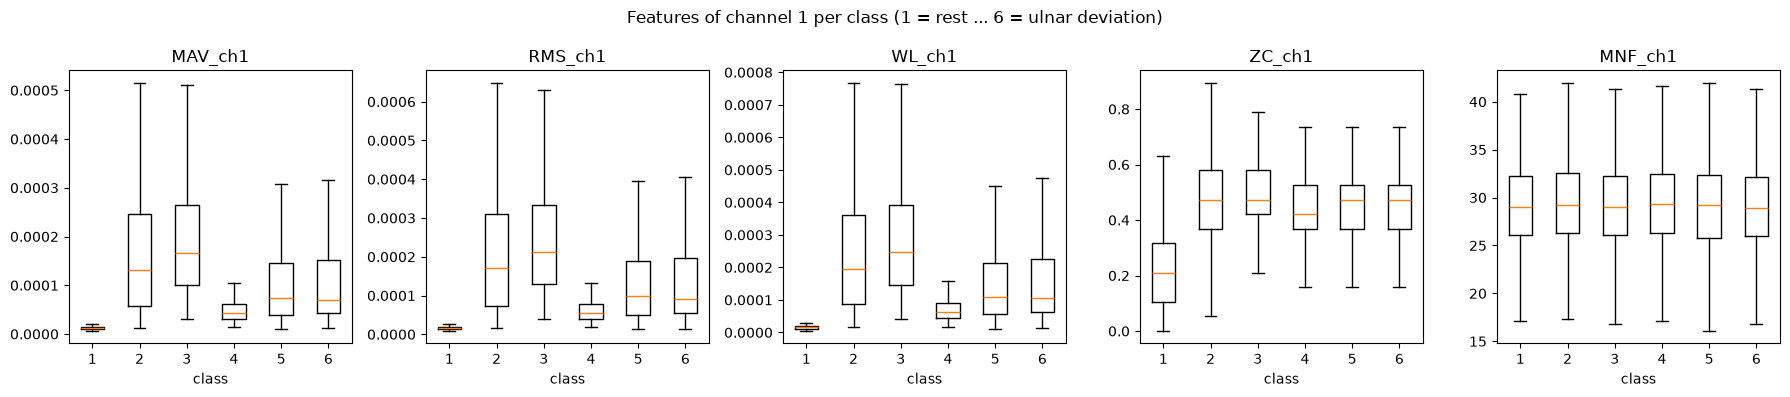

In [43]:
# Distribution of each feature type per class, for one channel
channel = 1
fig, axes = plt.subplots(1, 5, figsize=(18,4))
for i, f in enumerate(feature_types):
    column = f'{f}_ch{channel}'
    axes[i].boxplot([train.loc[train['class'] == c, column] for c in range(1, 7)], showfliers=False)
    axes[i].set_title(column)
    axes[i].set_xlabel('class')
plt.suptitle(f'Features of channel {channel} per class (1 = rest ... 6 = ulnar deviation)')
plt.tight_layout()
plt.show()

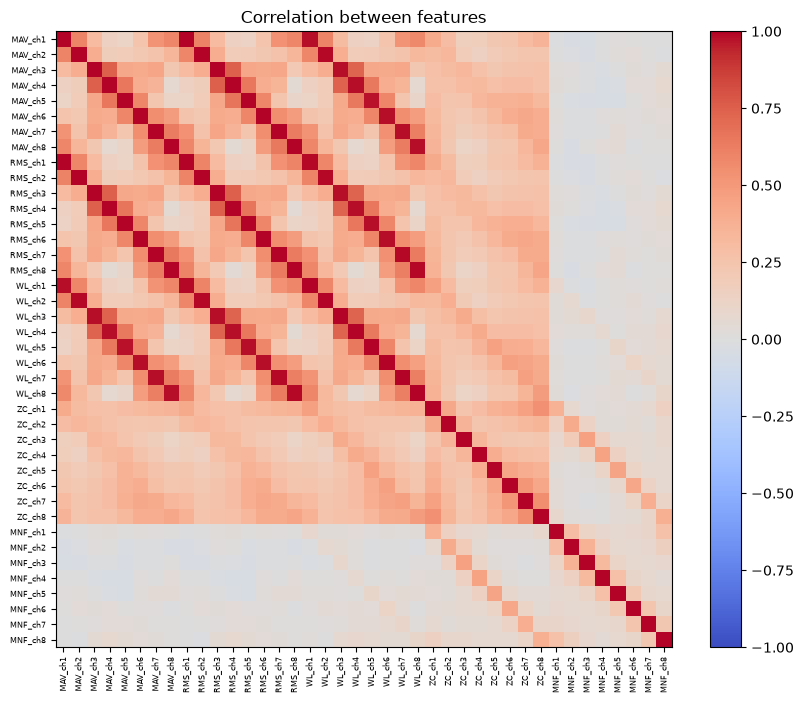

In [44]:
# Correlation matrix of all 40 features
corr_matrix = train[feature_names].corr()

plt.figure(figsize=(10,8))
plt.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(feature_names)), feature_names, rotation=90, fontsize=6)
plt.yticks(range(len(feature_names)), feature_names, fontsize=6)
plt.title('Correlation between features')
plt.show()

In [45]:
# Average correlation between two feature types (on the same channel)
type_corr = pd.DataFrame(index=feature_types, columns=feature_types, dtype=float)
for a in feature_types:
    for b in feature_types:
        type_corr.loc[a, b] = np.mean([corr_matrix.loc[f'{a}_ch{i}', f'{b}_ch{i}'] for i in range(1, 9)])
type_corr.round(2)

,MAV,RMS,WL,ZC,MNF
MAV,1.00,1.00,0.98,0.37,-0.01
RMS,1.00,1.00,0.98,0.37,-0.01
WL,0.98,0.98,1.00,0.44,0.09
ZC,0.37,0.37,0.44,1.00,0.41
MNF,-0.01,-0.01,0.09,0.41,1.00


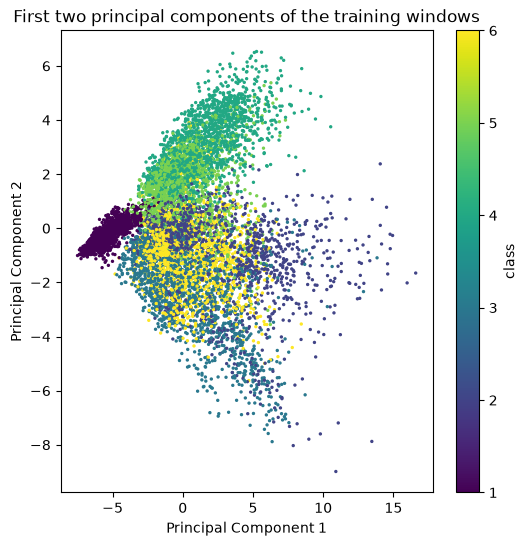

In [46]:
# PCA: project the standardized features onto the first 2 principal components
scaler = StandardScaler()
scaler.fit(train[feature_names])
x_train_scaled = scaler.transform(train[feature_names])

pca = PCA(n_components=2)
x_pca = pca.fit_transform(x_train_scaled)

plt.figure(figsize=(6,6))
plt.scatter(x_pca[:,0], x_pca[:,1], c=train['class'], cmap='viridis', s=2)
plt.colorbar(label='class')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('First two principal components of the training windows')
plt.show()

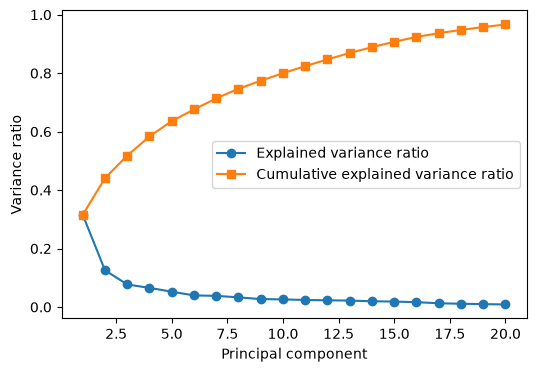

In [47]:
# Explained variance of the first 20 principal components
pca_20 = PCA(n_components=20)
pca_20.fit(x_train_scaled)

explained_var = pca_20.explained_variance_ratio_
cumulative_var = np.cumsum(explained_var)

plt.figure(figsize=(6,4))
plt.plot(range(1, 21), explained_var, marker='o', label='Explained variance ratio')
plt.plot(range(1, 21), cumulative_var, marker='s', label='Cumulative explained variance ratio')
plt.xlabel('Principal component')
plt.ylabel('Variance ratio')
plt.legend()
plt.show()

## 12. Standardization and feature selection

We compare feature sets on the **validation subjects** (Lectures 4 and 6). For every feature set:
1. A `StandardScaler` is fitted on the **training subjects only** and used to standardize training and validation data
   (fitting it on validation or test data would leak information).
2. A simple multi-class logistic regression (Lecture 3) is trained on the training subjects.
3. The predictions on the validation subjects are scored with the metrics from CodeLabs 3 and 4:
   **accuracy, precision, recall and F1 score** (macro average = the average over the 6 classes, every class counts equally),
   and a **confusion matrix** to see which gestures are confused.

The classes are balanced (about 2,500 windows each), so accuracy and F1 give similar values. For the selection we use the
**macro F1 score**, because it combines precision and recall and would also stay fair if a class were smaller.
The test subjects are not used.

In [51]:
def columns_of(types):
    # All column names of the given feature types, e.g. ['MAV'] -> ['MAV_ch1', ..., 'MAV_ch8']
    return [f'{t}_ch{i}' for t in types for i in range(1, 9)]

def evaluate_features(columns, train, val):
    # Fit the scaler and a logistic regression on the training subjects, score on the validation subjects
    scaler = StandardScaler()
    scaler.fit(train[columns])          # fitted on training subjects only
    model = LogisticRegression(max_iter=3000)
    model.fit(scaler.transform(train[columns]), train['class'])
    y_pred = model.predict(scaler.transform(val[columns]))

    scores = {'accuracy': accuracy_score(val['class'], y_pred),
              'precision': precision_score(val['class'], y_pred, average='macro'),
              'recall': recall_score(val['class'], y_pred, average='macro'),
              'f1': f1_score(val['class'], y_pred, average='macro')}
    return scores, y_pred

     accuracy  precision  recall     f1
MAV     0.871      0.877   0.872  0.873
RMS     0.865      0.870   0.867  0.866
WL      0.871      0.877   0.872  0.873
ZC      0.472      0.457   0.469  0.460
MNF     0.208      0.207   0.208  0.202


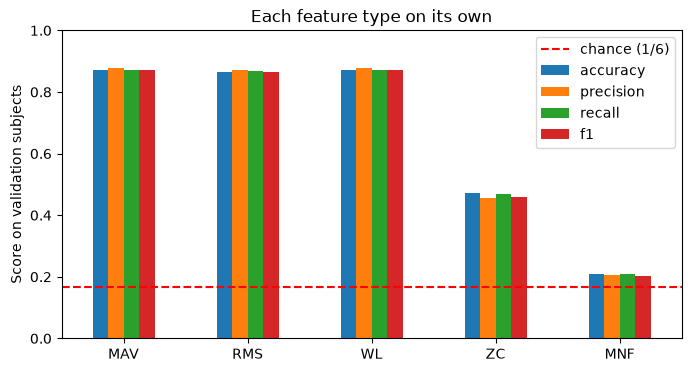

In [52]:
# Scores of every feature type on its own
results_per_type = pd.DataFrame(index=feature_types, columns=['accuracy', 'precision', 'recall', 'f1'], dtype=float)
for f in feature_types:
    scores, y_pred = evaluate_features(columns_of([f]), train, val)
    results_per_type.loc[f] = scores
print(results_per_type.round(3))

results_per_type.plot(kind='bar', figsize=(8,4))
plt.axhline(1/6, color='r', linestyle='--', label='chance (1/6)')
plt.ylim(0, 1)
plt.ylabel('Score on validation subjects')
plt.title('Each feature type on its own')
plt.xticks(rotation=0)
plt.legend()
plt.show()

['MAV'] accuracy: 0.871 precision: 0.877 recall: 0.872 f1: 0.873
['MAV', 'WL'] accuracy: 0.875 precision: 0.881 recall: 0.876 f1: 0.877
['MAV', 'WL', 'ZC'] accuracy: 0.870 precision: 0.876 recall: 0.871 f1: 0.871
['MAV', 'WL', 'ZC', 'MNF'] accuracy: 0.870 precision: 0.874 recall: 0.871 f1: 0.871
['MAV', 'WL', 'ZC', 'MNF', 'RMS'] accuracy: 0.866 precision: 0.870 recall: 0.867 f1: 0.867


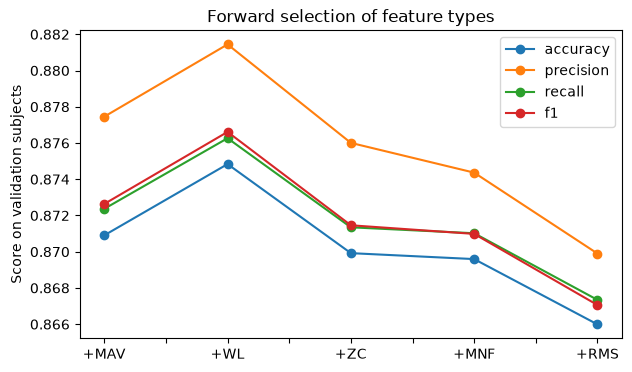

In [53]:
# Forward selection: start with no features and add, one at a time, the feature type that gives the highest validation F1 score
selected = []
remaining = feature_types.copy()
forward_results = []

while len(remaining) > 0:
    f1_scores = [evaluate_features(columns_of(selected + [f]), train, val)[0]['f1'] for f in remaining]
    best = remaining[np.argmax(f1_scores)]
    selected.append(best)
    remaining.remove(best)
    scores, y_pred = evaluate_features(columns_of(selected), train, val)
    forward_results.append(scores)
    print(selected, ' '.join('%s: %.3f' % (k, v) for k, v in scores.items()))

forward_results = pd.DataFrame(forward_results, index=['+' + s for s in selected])
forward_results.plot(marker='o', figsize=(7,4))
plt.ylabel('Score on validation subjects')
plt.title('Forward selection of feature types')
plt.show()

accuracy: 0.871 precision: 0.877 recall: 0.872 f1: 0.873


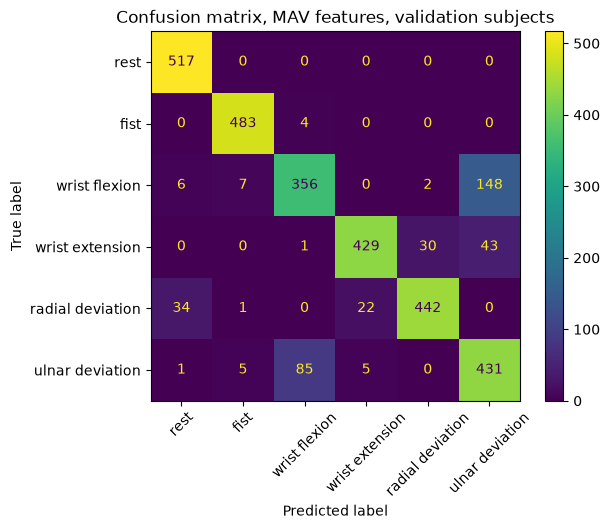

In [54]:
# Confusion matrix of the selected feature set (MAV) on the validation subjects
scores, y_pred = evaluate_features(columns_of(['MAV']), train, val)
print(' '.join('%s: %.3f' % (k, v) for k, v in scores.items()))

conf_matrix = confusion_matrix(val['class'], y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=[class_names[c] for c in range(1, 7)])
disp.plot(xticks_rotation=45)
plt.title('Confusion matrix, MAV features, validation subjects')
plt.show()

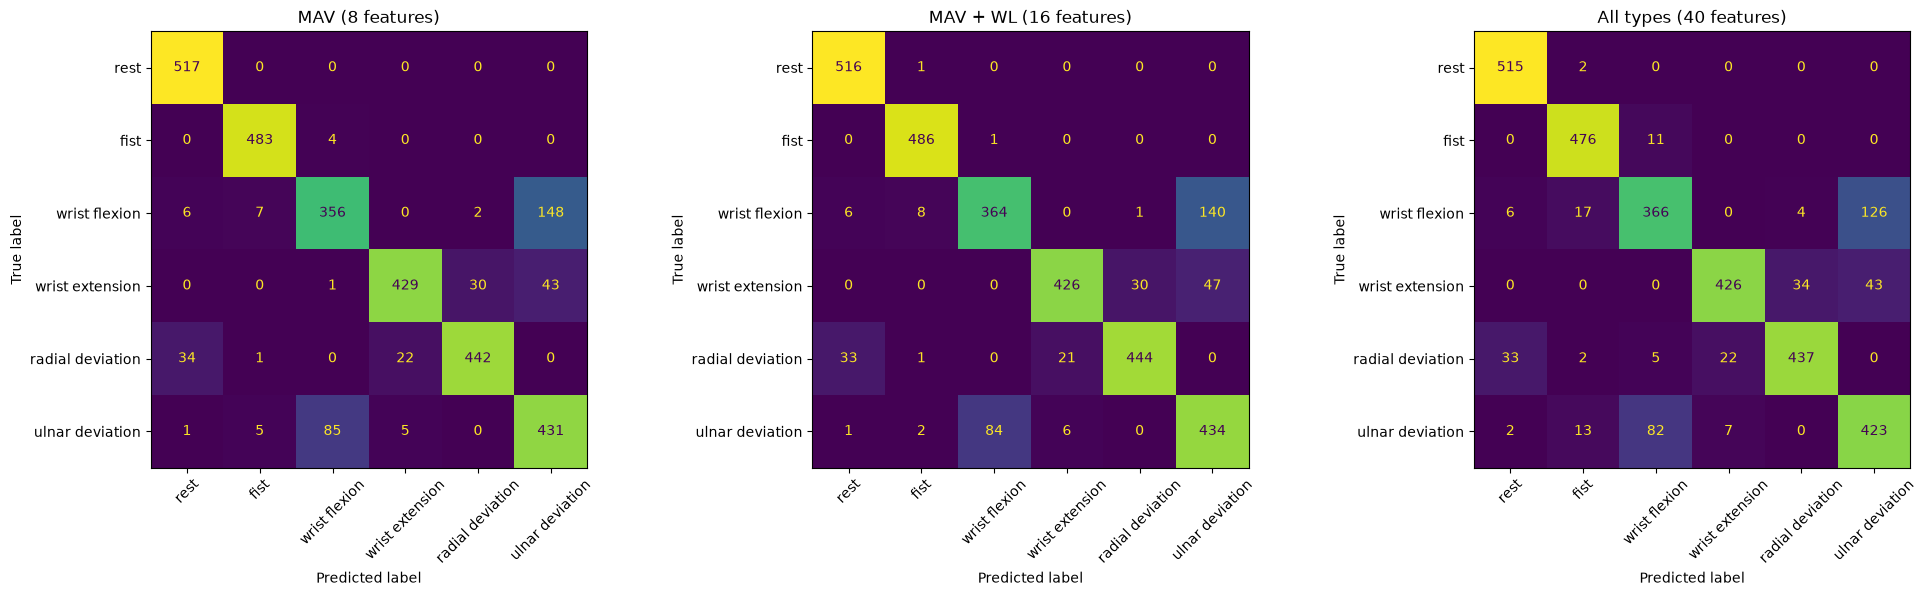

,accuracy,precision,recall,f1
MAV (8 features),0.871,0.877,0.872,0.873
MAV + WL (16 features),0.875,0.881,0.876,0.877
All types (40 features),0.866,0.870,0.867,0.867


In [56]:
# Compare feature sets with fewer and more features: scores and confusion matrices on the validation subjects
feature_sets = {'MAV (8 features)': ['MAV'],
                'MAV + WL (16 features)': ['MAV', 'WL'],
                'All types (40 features)': feature_types}

results_sets = pd.DataFrame(index=feature_sets.keys(), columns=['accuracy', 'precision', 'recall', 'f1'], dtype=float)
fig, axes = plt.subplots(1, 3, figsize=(20,6))
for ax, (name, types) in zip(axes, feature_sets.items()):
    scores, y_pred = evaluate_features(columns_of(types), train, val)
    results_sets.loc[name] = scores
    conf_matrix = confusion_matrix(val['class'], y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=[class_names[c] for c in range(1, 7)])
    disp.plot(ax=ax, xticks_rotation=45, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

results_sets.round(3)

In [57]:
# Effect of the window length (with MAV features, 50% overlap)
results_per_size = []
for size in [10, 20, 30, 40]:
    f = make_feature_table(data_clean, size, size // 2, fs)
    scores, y_pred = evaluate_features(columns_of(['MAV']), f[f['subject'].isin(train_subjects)], f[f['subject'].isin(val_subjects)])
    scores['windows'] = len(f)
    results_per_size.append(scores)
results_per_size = pd.DataFrame(results_per_size, index=['%d samples (%.0f ms)' % (s, s / fs * 1000) for s in [10, 20, 30, 40]])
results_per_size.round(3)

,accuracy,precision,recall,f1,windows
10 samples (95 ms),0.866,0.872,0.867,0.867,31452
20 samples (190 ms),0.871,0.877,0.872,0.873,15069
30 samples (286 ms),0.872,0.881,0.874,0.875,9613
40 samples (381 ms),0.868,0.878,0.870,0.871,6905


Results of the feature analysis and selection (scores on the validation subjects, macro averages):
- **MAV, RMS and WL are almost the same information** (correlation 0.98-1.00). On their own they all score about 0.87
  (accuracy, precision, recall and F1). Keeping all three adds features but no information.
- **ZC is weaker** (F1 0.46 on its own) and **MNF is close to chance** (F1 0.20, chance = 0.17).
  For MNF this is expected: with 20 unevenly spaced samples the frequency estimate is very rough.
- **PCA:** rest forms a separate cluster; the other gestures overlap in 2 dimensions. The first 2 components explain about 44%
  of the variance, so the information is spread over many features.
- **Forward selection:** MAV alone F1 0.873, MAV + WL 0.877; adding more feature types does not help (0.867-0.871).
  The difference between MAV and MAV + WL (0.4%, about 12 of 3052 windows) is too small to be meaningful.
- **Confusion matrix (MAV):** rest and fist are almost perfect. The main error is **wrist flexion vs. ulnar deviation**
  (148 flexion windows predicted as ulnar deviation, 85 the other way round), followed by radial deviation vs. rest/extension.
  Precision and recall are close to each other, so no class is systematically over- or under-predicted.
- **Window length:** 10-40 samples give almost the same scores (F1 0.867-0.875). We keep **20 samples (about 190 ms)**:
  short enough for real-time use and it gives more windows than longer windows.

Decision: **MAV** (8 features) is the main feature set, because simpler is better when the scores are the same (Lecture 6, parsimony).
This selection was made with a linear model; a nonlinear model (Task 2) might still use ZC or MNF, so we also keep the
full set of 40 features as a second candidate and compare both in Task 2.


## Summary of Task 1

| Step | Choice | Reason |
|---|---|---|
| Preparation | Remove class 0 (unmarked) and class 7 (extended palm) | Class 0 is pauses and transitions, not one gesture; class 7 was performed by only 2 subjects |
| Cleaning | Remove repeated rows (89%) | They are copies written by the recording software; real sampling rate is about 105 Hz |
| Windowing | 20 samples (about 190 ms), 50% overlap, inside one gesture block | Single samples carry almost no information; 10-40 samples score the same |
| Feature construction | MAV, RMS, WL, ZC, MNF per channel (40 features) | Common time- and frequency-domain EMG features |
| Split | By subject: 22 train, 7 validation, 7 test | Tests whether the model works for a new person and avoids leakage between similar windows |
| Standardization | `StandardScaler` fitted on training subjects only | Features have very different scales; fitting on other sets would leak information |
| Feature selection | **MAV (8 features)** as main set, all 40 features as second candidate | MAV, RMS and WL are nearly identical (correlation 0.98-1.00); more features do not improve the linear model |

Result: logistic regression with MAV features reaches **macro F1 0.873** on the validation subjects (chance = 0.17).
The output of Task 1 is the table `features` (15,069 windows) and the subject split, which are the input for Task 2.